# FAMED-Net


In [1]:
from pathlib import Path
import re
import subprocess
import sys
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

METHOD = 'famednet'
LABEL = 'FAMED-Net'



## Data


In [3]:
# Locate the project when running locally.
REPO_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                  if (p / 'dehazing' / 'methods').is_dir()), None)
if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = Path('/content/drive/MyDrive')
    WORK = Path('/content/dehaze_upstream')
else:
    BASE_DIR = REPO_ROOT or Path.cwd()
    WORK = BASE_DIR / '.dehaze_upstream'

RESIZE = 1600                 # Maximum long edge. Use 800 for O-HAZE-800.
MAX_IMAGES = None                # Set to None to run every pair.
# SRC = BASE_DIR / 'O-HAZE'     # Original dataset with hazy/ and GT/
SRC = Path(r"C:\Users\Lenovo\Desktop\Project in Software Development in Image Analysis and Machine Learning\O-HAZE")
DATA_ROOT = BASE_DIR / (f'O-HAZE-{RESIZE}' if RESIZE > 0 else 'O-HAZE-native')
OUT = BASE_DIR / 'outputs' / METHOD


In [5]:
IMAGE_SUFFIXES = {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp'}


def image_index(folder):
    indexed = {}
    for path in sorted(folder.iterdir()):
        if not path.is_file() or path.suffix.lower() not in IMAGE_SUFFIXES:
            continue
        key = re.sub(r'[_-](?:hazy|gt|clear)$', '', path.stem.lower())
        if key in indexed:
            raise ValueError(f'Duplicate image pair key {key}: {indexed[key]} and {path}')
        indexed[key] = path
    return indexed


def paired_images(root):
    hazy = image_index(root / 'hazy')
    gt = image_index(root / 'GT')
    if not hazy or set(hazy) != set(gt):
        raise ValueError(f'{root}: check hazy/ and GT/ pairing. '
                         f'Missing GT: {sorted(hazy.keys() - gt.keys())}; '
                         f'missing hazy: {sorted(gt.keys() - hazy.keys())}')
    return sorted(((hazy[key], gt[key]) for key in hazy), key=lambda pair: pair[0].name)


def read_rgb(path):
    with Image.open(path) as im:
        return im.convert('RGB')


def save_png(image, path):
    pending = path.with_name('.' + path.name + '.part')
    image.save(pending, format='PNG')
    pending.replace(path)


if all((SRC / name).is_dir() for name in ('hazy', 'GT')):
    if SRC.resolve() == DATA_ROOT.resolve():
        raise ValueError('SRC and DATA_ROOT must be separate folders.')
    for name in ('hazy', 'GT'):
        (DATA_ROOT / name).mkdir(parents=True, exist_ok=True)
    for hazy_file, gt_file in paired_images(SRC):
        hazy_out = DATA_ROOT / 'hazy' / (hazy_file.stem + '.png')
        gt_out = DATA_ROOT / 'GT' / (gt_file.stem + '.png')
        if hazy_out.is_file() and gt_out.is_file():
            continue
        hazy = read_rgb(hazy_file)
        scale = min(1.0, RESIZE / max(hazy.size)) if RESIZE > 0 else 1.0
        size = tuple(max(1, round(v * scale)) for v in hazy.size)
        save_png(hazy.resize(size, Image.Resampling.BICUBIC), hazy_out)
        save_png(read_rgb(gt_file).resize(size, Image.Resampling.BICUBIC), gt_out)
elif not all((DATA_ROOT / name).is_dir() for name in ('hazy', 'GT')):
    raise FileNotFoundError(f'Set SRC to an O-HAZE folder with hazy/ and GT/. Checked: {SRC}')

if MAX_IMAGES is not None and MAX_IMAGES < 1:
    raise ValueError('MAX_IMAGES must be positive or None.')
pairs = paired_images(DATA_ROOT)[:MAX_IMAGES]
for hazy_path, gt_path in pairs:
    with Image.open(hazy_path) as hazy, Image.open(gt_path) as gt:
        if hazy.size != gt.size or (RESIZE > 0 and max(hazy.size) > RESIZE):
            raise ValueError(f'Recreate {DATA_ROOT} at the configured RESIZE. Check {hazy_path.name}.')
OUT.mkdir(parents=True, exist_ok=True)
print(f'{len(pairs)} image(s) | Input: {DATA_ROOT} | Output: {OUT}')


5 image(s) | Input: C:\Users\Lenovo\Desktop\Project in Software Development in Image Analysis and Machine Learning\github\vidhance-extendview\O-HAZE-800 | Output: C:\Users\Lenovo\Desktop\Project in Software Development in Image Analysis and Machine Learning\github\vidhance-extendview\outputs\famednet


## Pretrained weights
Public weights are downloaded by default. For local weights, keep `deploy.prototxt` next to the `.caffemodel` file.


In [8]:
CHECKPOINT = None             # Or path to FAMED-Net.caffemodel, next to deploy.prototxt.

import torch
import torch.nn as nn
import torch.nn.functional as F

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch {torch.__version__} | Device: {DEVICE}')

from urllib.request import urlopen
from shutil import copyfileobj


def fetch_upstream(repo, revision, files):
    """Cache only the files needed from the pinned upstream revision."""
    root = WORK / 'upstream' / f"{repo.replace('/', '--')}-{revision[:8]}"
    base = f'https://raw.githubusercontent.com/{repo}/{revision}'
    for name in files:
        target = root / name
        if target.is_file() and target.stat().st_size > 0:
            continue
        target.parent.mkdir(parents=True, exist_ok=True)
        pending = target.with_name(target.name + '.part')
        try:
            with urlopen(f'{base}/{name}', timeout=90) as source, pending.open('wb') as output:
                copyfileobj(source, output)
            pending.replace(target)
        except OSError as error:
            raise RuntimeError(f'无法获取 {repo}/{name}。请检查网络，或在 CHECKPOINT 设置本地权重路径。') from error
        finally:
            pending.unlink(missing_ok=True)
    return root


import importlib.util
import subprocess

if importlib.util.find_spec('cv2') is None:
    subprocess.run([
        sys.executable, '-m', 'pip', 'install', '--quiet', '--no-deps',
        '--only-binary=:all:', 'opencv-python-headless==4.11.0.86',
    ], check=True)
import cv2

if CHECKPOINT is None:
    model_dir = 'FAMED-Net/model/FAMED-Net'
    REPO = fetch_upstream(
        'chaimi2013/FAMED-Net', '37999d085fc71a44e37c25ed42c581b5b367805b',
        (f'{model_dir}/deploy.prototxt', f'{model_dir}/FAMED-Net.caffemodel'),
    )
    CKPT = REPO / model_dir / 'FAMED-Net.caffemodel'
else:
    CKPT = Path(CHECKPOINT)

DEPLOY = CKPT.with_name('deploy.prototxt')
for path in (CKPT, DEPLOY):
    if not path.is_file():
        raise FileNotFoundError(f'请将 FAMED-Net.caffemodel 和匹配的 deploy.prototxt 放在同一目录。缺少 {path}')

import tempfile


def read_famed_weights(deploy, checkpoint):
    # Extract Caffe blobs in a separate process so cv2 versions stay isolated.
    extract = """
import sys
sys.path.insert(0, sys.argv[1])
import cv2
import numpy as np

if not hasattr(cv2.dnn, 'readNetFromCaffe'):
    sys.exit(42)

net = cv2.dnn.readNetFromCaffe(sys.argv[2], sys.argv[3])

def blobs(name):
    layer_id = net.getLayerId(name)
    if layer_id < 0:
        raise ValueError(f'Missing FAMED-Net layer: {name}')
    return net.getLayer(layer_id).blobs

parameters = {}
for scale, suffix in enumerate(('', '-ds2', '-ds4')):
    for index in range(1, 6):
        name = f'conv{index}{suffix}'
        kernel, bias = blobs(name)
        bias = bias.reshape(-1)
        if index < 5:
            # Fold Caffe BatchNorm and Scale into the preceding convolution.
            mean, variance, count = blobs('bn_' + name)
            gamma, beta = blobs('scale_' + name)
            count = count.item()
            inv_count = np.float32(1 / count if count else 0)
            mean = mean.reshape(-1) * inv_count
            variance = variance.reshape(-1) * inv_count
            gain = gamma.reshape(-1) / np.sqrt(variance + np.float32(1e-5))
            kernel = kernel * gain[:, None, None, None]
            bias = (bias - mean) * gain + beta.reshape(-1)
        key = f'encoders.{scale}.convs.{index - 1}'
        parameters[key + '.weight'] = kernel
        parameters[key + '.bias'] = bias

kernel, bias = blobs('conv5-fusion')
parameters['fusion.weight'] = kernel
parameters['fusion.bias'] = bias.reshape(-1)
np.savez(sys.argv[4], **parameters)
"""
    with tempfile.TemporaryDirectory(prefix='famed-caffe-') as temporary:
        opencv_dir = Path(temporary) / 'opencv'
        archive = Path(temporary) / 'weights.npz'
        command = [sys.executable, '-c', extract, str(opencv_dir), str(deploy),
                   str(checkpoint), str(archive)]
        result = subprocess.run(command)
        if result.returncode == 42:
            subprocess.run([
                sys.executable, '-m', 'pip', 'install', '--quiet', '--no-deps',
                '--only-binary=:all:', '--target', str(opencv_dir),
                'opencv-python-headless==4.11.0.86',
            ], check=True)
            subprocess.run(command, check=True)
        else:
            result.check_returncode()
        with np.load(archive, allow_pickle=False) as saved:
            return {name: torch.from_numpy(saved[name]) for name in saved.files}


PyTorch 2.8.0+cpu | Device: cpu


## Model


In [10]:
class FamedEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.convs = nn.ModuleList([
            nn.Conv2d(3, 32, 1),
            nn.Conv2d(32, 32, 1),
            nn.Conv2d(64, 32, 1),
            nn.Conv2d(64, 32, 1),
            nn.Conv2d(128, 3, 1),
        ])

    def forward(self, x):
        first = self.convs[0](x).relu()
        pool1 = F.max_pool2d(self.convs[1](first).relu(), 3, stride=1, padding=1)
        second = self.convs[2](torch.cat((first, pool1), dim=1)).relu()
        pool2 = F.max_pool2d(second, 5, stride=1, padding=2)
        third = self.convs[3](torch.cat((pool1, pool2), dim=1)).relu()
        pool3 = F.max_pool2d(third, 7, stride=1, padding=3)
        return self.convs[4](torch.cat((first, pool1, pool2, pool3), dim=1)).relu()


class FamedNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoders = nn.ModuleList(FamedEncoder() for _ in range(3))
        self.fusion = nn.Conv2d(9, 3, 1)

    def forward(self, x):
        h, w = x.shape[-2:]
        estimates = [self.encoders[0](x)]
        for encoder, shrink in zip(self.encoders[1:], (2, 4)):
            # Match the Caffe Interp output size and align-corners sampling.
            size = ((h - 1) // shrink + 1, (w - 1) // shrink + 1)
            low = F.interpolate(x, size=size, mode='bilinear', align_corners=True)
            estimate = encoder(low)
            estimates.append(F.interpolate(
                estimate, size=(h, w), mode='bilinear', align_corners=True
            ))
        return self.fusion(torch.cat(estimates, dim=1)).relu()

net = FamedNet()
net.load_state_dict(read_famed_weights(DEPLOY, CKPT), strict=True)
net = net.to(DEVICE).eval()
print(f'Weights: {CKPT} | FAMED-Net backend: PyTorch {DEVICE}')


Weights: C:\Users\Lenovo\Desktop\Project in Software Development in Image Analysis and Machine Learning\github\vidhance-extendview\.dehaze_upstream\upstream\chaimi2013--FAMED-Net-37999d08\FAMED-Net\model\FAMED-Net\FAMED-Net.caffemodel | FAMED-Net backend: PyTorch cpu


## Method


In [12]:
def fast_guided_filter(guide, values, radius=48, eps=1e-4, subsample=4):
    h, w = guide.shape
    small = ((w + subsample - 1) // subsample, (h + subsample - 1) // subsample)
    g = cv2.resize(guide, small, interpolation=cv2.INTER_NEAREST_EXACT)
    v = cv2.resize(values, small, interpolation=cv2.INTER_NEAREST_EXACT)
    window = 2 * (radius // subsample) + 1

    def box(x):
        return cv2.boxFilter(x, -1, (window, window), normalize=False,
                             borderType=cv2.BORDER_CONSTANT)

    count = box(np.ones_like(g))
    mean_g, mean_v = box(g) / count, box(v) / count
    cov = box(g * v) / count - mean_g * mean_v
    var = box(g * g) / count - mean_g ** 2
    a = cov / (var + eps)
    b = mean_v - a * mean_g
    a = cv2.resize(box(a) / count, (w, h), interpolation=cv2.INTER_LINEAR)
    b = cv2.resize(box(b) / count, (w, h), interpolation=cv2.INTER_LINEAR)
    return a * guide + b


@torch.inference_mode()
def dehaze(hazy):
    """PIL RGB image -> float RGB array at the original evaluation size."""
    image = np.asarray(hazy, dtype=np.float32) / 255
    h, w = image.shape[:2]
    scale = 360 / max(h, w)
    size = (max(1, round(w * scale)), max(1, round(h * scale)))
    small = cv2.resize(image, size, interpolation=cv2.INTER_CUBIC)
    batch = torch.from_numpy(np.ascontiguousarray(small.transpose(2, 0, 1)[None])).to(DEVICE)
    k = net(batch)[0].permute(1, 2, 0).cpu().numpy()
    k = cv2.resize(k, (w, h), interpolation=cv2.INTER_CUBIC)
    guide = image.max(axis=2)
    k = np.stack([fast_guided_filter(guide, k[:, :, c]) for c in range(3)], axis=2)
    return k * image - k + 1


## Run over the dataset


In [14]:
for hazy_path, _ in pairs:
    hazy = read_rgb(hazy_path)
    with torch.inference_mode():
        if DEVICE.type == 'cuda':
            torch.cuda.synchronize()
        t0 = perf_counter()
        prediction = dehaze(hazy)
        if DEVICE.type == 'cuda':
            torch.cuda.synchronize()
        elapsed_ms = (perf_counter() - t0) * 1000
    if prediction.shape != (hazy.height, hazy.width, 3) or not np.isfinite(prediction).all():
        raise ValueError(f'{LABEL}: invalid RGB prediction for {hazy_path.name} ({prediction.shape}).')
    output = Image.fromarray(np.rint(np.clip(prediction, 0, 1) * 255).astype(np.uint8))
    target = OUT / hazy_path.name
    pending = target.with_name('.' + target.stem + '.part' + target.suffix)
    output.save(pending)
    pending.replace(target)
    print(f'{hazy_path.name} | {hazy.width}x{hazy.height} | {elapsed_ms:.1f} ms')


01_outdoor_hazy.png | 741x800 | 480.4 ms
02_outdoor_hazy.png | 641x800 | 391.9 ms
03_outdoor_hazy.png | 800x533 | 333.8 ms
04_outdoor_hazy.png | 663x800 | 386.9 ms
05_outdoor_hazy.png | 800x632 | 447.2 ms


## Preview


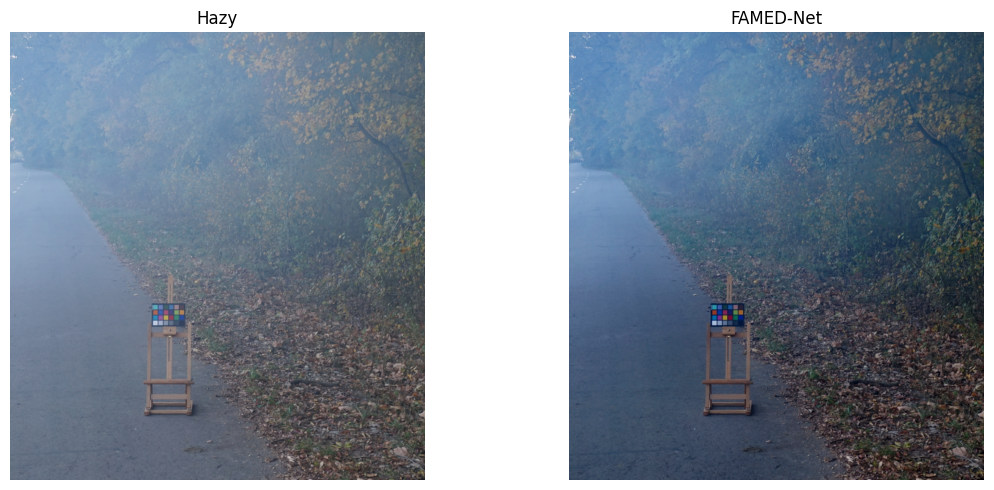

In [16]:
hazy_path, _ = pairs[0]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, path, title in zip(axes, (hazy_path, OUT / hazy_path.name), ('Hazy', LABEL)):
    ax.imshow(read_rgb(path))
    ax.set_title(title)
    ax.axis('off')
fig.tight_layout()
plt.show()
